# Fit Al 2024 Hugoniot


In [1]:
import os
from os.path import exists

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import os
from os.path import exists

# Impedance Match Calculation classes and functions
import IM_module as IM # classes and functions for this impedance match notebook

# Collect files needed to run this notebook in the cloud (e.g., Google CoLab)
use_local_files = True # prefer local files than GitHub repo (change to false to refresh from repo)


## About the IM_module

The IM_module contains several function to interact with the shock Hugoniot data.
Use the command help(IM) to list the classes and functions.


In [2]:
# uncomment the command below for information about the module
#help(IM)

## Step 1: load the material-data.csv file

Load the material database with the following comment.
The parameters are stored in a DataFrame object called matdata.
The imat object contains indexing information for book-keeping purposes in the code.
If you want to change the format of the database, update the material indices function to preserve the code functionality.

For ease of use the materials database file uses g/cm3 and km/s, as is most common in the shockwave literature.

The file is converted to MKS when it is read in and all the functions are expecting MKS units.

In [3]:
# load the materials data table; change matfilename if not using default
matdata, imat = IM.ReadMaterials(matfilename='materials-data.csv')


## Plotting the data and fits

Examples of initializing material objects, fitting, and plotting functions.

P = 163.4 (GPa), u<sub>p</sub> = 2.5 (km/s), U<sub>S</sub> = 0.0 (km/s), E = 3.12 (MJ/kg), &#961; = 11.26 (g/cm<sup>3</sup>)
P = 163.4 (GPa), u<sub>p</sub> = 2.5 (km/s), U<sub>S</sub> = 8.3 (km/s), E = 3.12 (MJ/kg), &#961; = 11.26 (g/cm<sup>3</sup>)
163400875000.0
2500.0


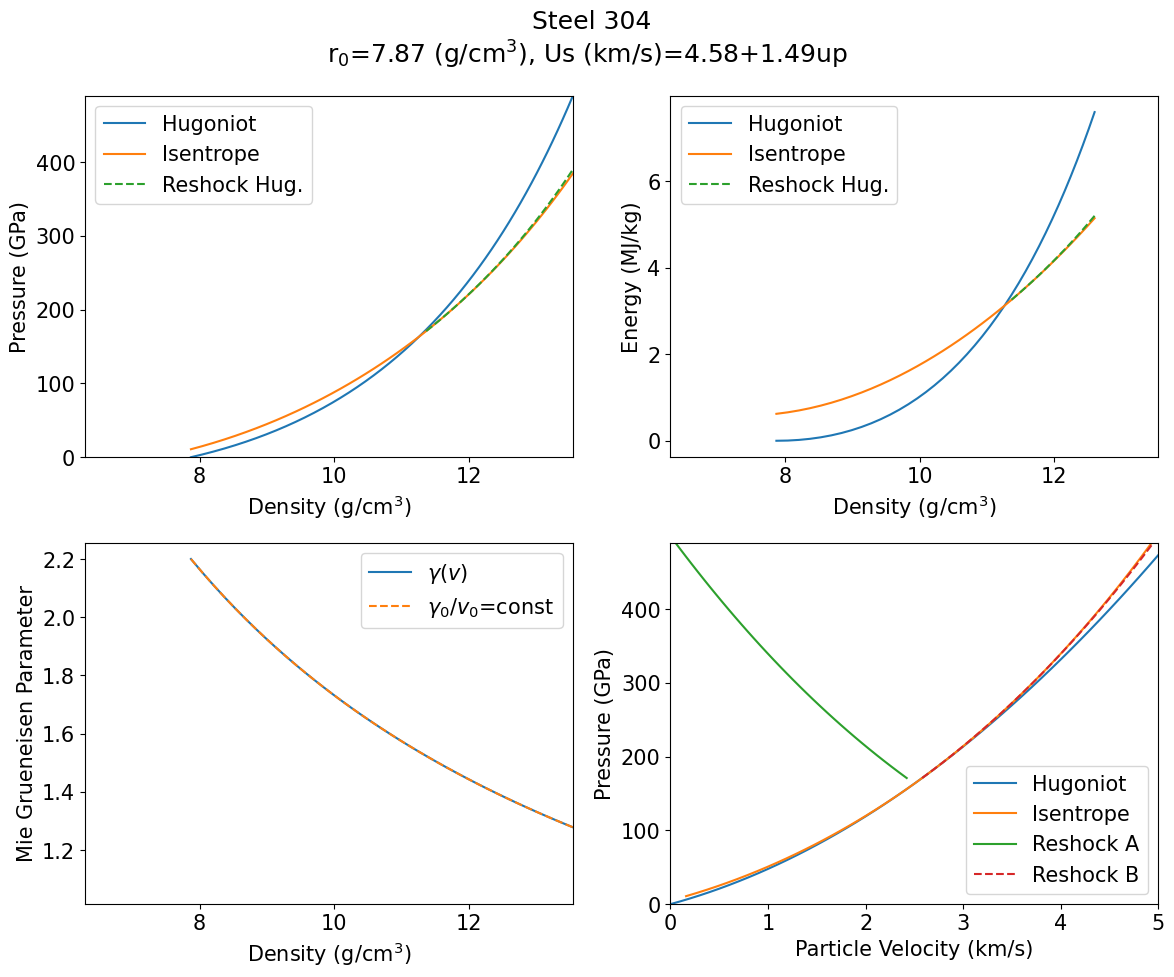

In [4]:
# hopefully everything in mks
up =np.arange(101)/100.*10000

mat1 = IM.Material() # create material object named 'mat3'
matname='Steel 304' # material name in the material-data.csv file
mat1.DefineParamsID(matname,matdata,imat) # load the parameters for this material
mat1.MakeHugoniot(up)

mat2 = IM.Material() # create material object named 'mat3'
matname='Steel 304' # material name in the material-data.csv file
mat2.DefineParamsID(matname,matdata,imat) # load the parameters for this material
mat2.MakeHugoniot(up)

mat3 = IM.Material() # create material object named 'mat3'
matname='Fused-qtz-all' # material name in the material-data.csv file
mat3.DefineParamsID(matname,matdata,imat) # load the parameters for this material
mat3.MakeHugoniot(up)

vel=5000. # m/s
IM12_success = mat1.IM_match(mat2,vel=vel)

print(mat1.im1)
print(mat2.im1)
print(mat2.im1.p)
print(mat2.im1.up)
mat2.PlotCurves(mat2.im1.p,usemgmodelbool=True,impvel=vel)


P = 163.4 (GPa), u<sub>p</sub> = 2.5 (km/s), U<sub>S</sub> = 0.0 (km/s), E = 3.12 (MJ/kg), &#961; = 11.26 (g/cm<sup>3</sup>)
P = 22.26 (GPa), u<sub>p</sub> = 1.97 (km/s), U<sub>S</sub> = 8.3 (km/s), E = 1.95 (MJ/kg), &#961; = 10.67 (g/cm<sup>3</sup>)
P = 22.26 (GPa), u<sub>p</sub> = 1.97 (km/s), U<sub>S</sub> = 5.12 (km/s), E = 1.95 (MJ/kg), &#961; = 3.59 (g/cm<sup>3</sup>)


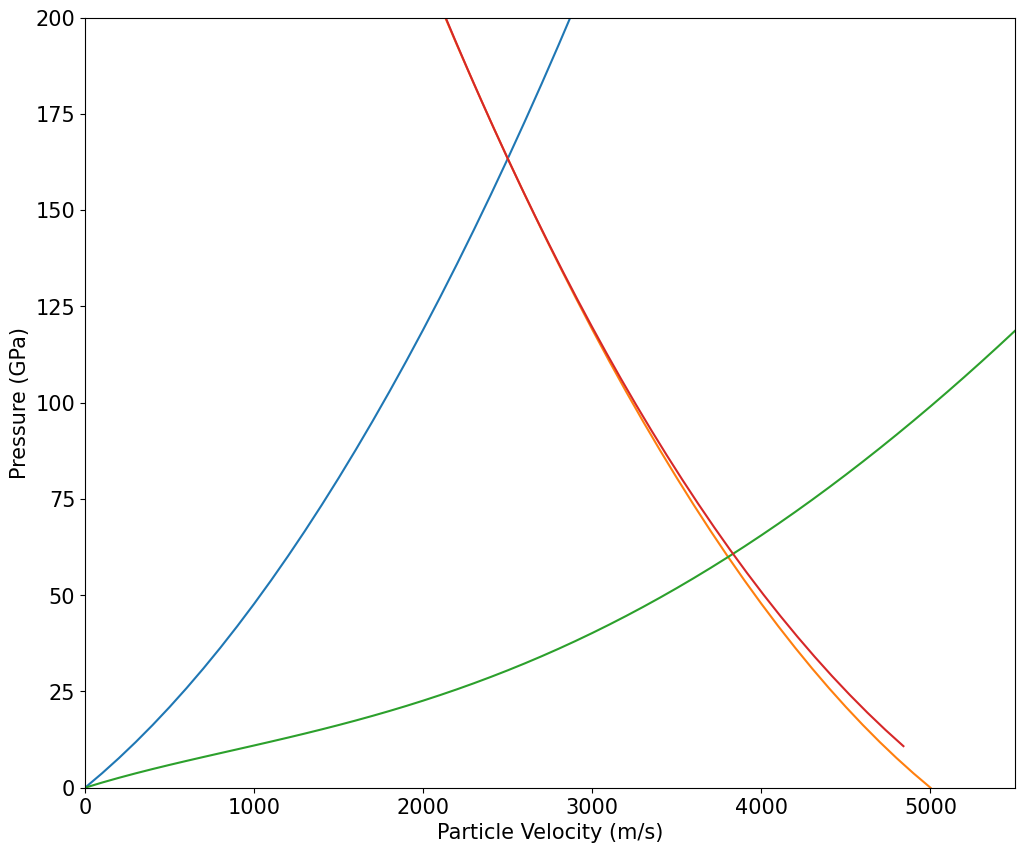

In [5]:
plt.plot(mat2.hug.uparr,mat2.hug.parr/1.e9)
plt.plot(vel-mat1.hug.uparr,mat1.hug.parr/1.e9)
plt.plot(mat3.hug.uparr,mat3.hug.parr/1.e9)

plt.xlabel('Particle Velocity (m/s)')
plt.ylabel('Pressure (GPa)')
plt.ylim([0,200])
plt.xlim([0,5500])


IM23_success = mat2.IM_match(mat3,vel=mat2.im1.up)
print(mat1.im1) # original flyer->driver IM
print(mat2.im1) # overwrites this state to new IM solution
print(mat3.im1) # target IM

plt.plot(2.*mat1.im1.up-mat2.isen.uparr,mat2.isen.parr/1.e9)


In [6]:
duffy = pd.read_csv('database-user/Duffy-Table6.csv')

In [7]:
display(duffy)

,Shot,Up km/s,Up_err,Us km/s,Us_err,Rho g/cm3,Rho_err,Stress GPa,Stress_err
0,746,0.209,0.005,4.891,0.011,8.208,0.019,8.1,0.2
1,747,0.170,0.003,4.834,0.011,8.119,0.013,6.5,0.1
2,749,0.239,0.004,4.936,0.012,8.257,0.011,9.3,0.1
3,771,0.288,0.012,5.010,0.021,8.298,0.024,11.3,0.5
4,802,0.575,0.008,5.437,0.016,8.810,0.013,24.6,0.4
5,804,0.970,0.006,6.025,0.090,9.385,0.086,46.0,3.6
6,809,1.183,0.024,6.342,0.038,9.630,0.035,58.7,1.5
7,812,1.458,0.022,6.753,0.370,9.983,0.041,77.1,1.6
8,813,0.597,0.008,5.470,0.016,8.831,0.013,25.7,4.0
9,847,1.447,0.015,6.736,0.027,10.050,0.022,76.9,1.1


In [8]:
duffy_up = np.asarray(duffy['Up km/s'])*1000.
print(duffy_up)
duffy_us = np.asarray(duffy['Us km/s'])*1000.
print(duffy_us)
moredata = np.concatenate(([7870],duffy_up,duffy_us))


[ 209.  170.  239.  288.  575.  970. 1183. 1458.  597. 1447. 1485.]
[4891. 4834. 4936. 5010. 5437. 6025. 6342. 6753. 5470. 6736. 6793.]


Including user data
Stainless steel 304 Steel 304 fit (mks) c0= 4596.26887151552  s1= 1.4739547307133403  s2= 0.0  d= 0.0
N=33. Fit stdev (km/s)=0.03705410249225906
Primary Hugoniot parameters c0,s1,s2,d= 4580.0 1.49 0.0 0.0


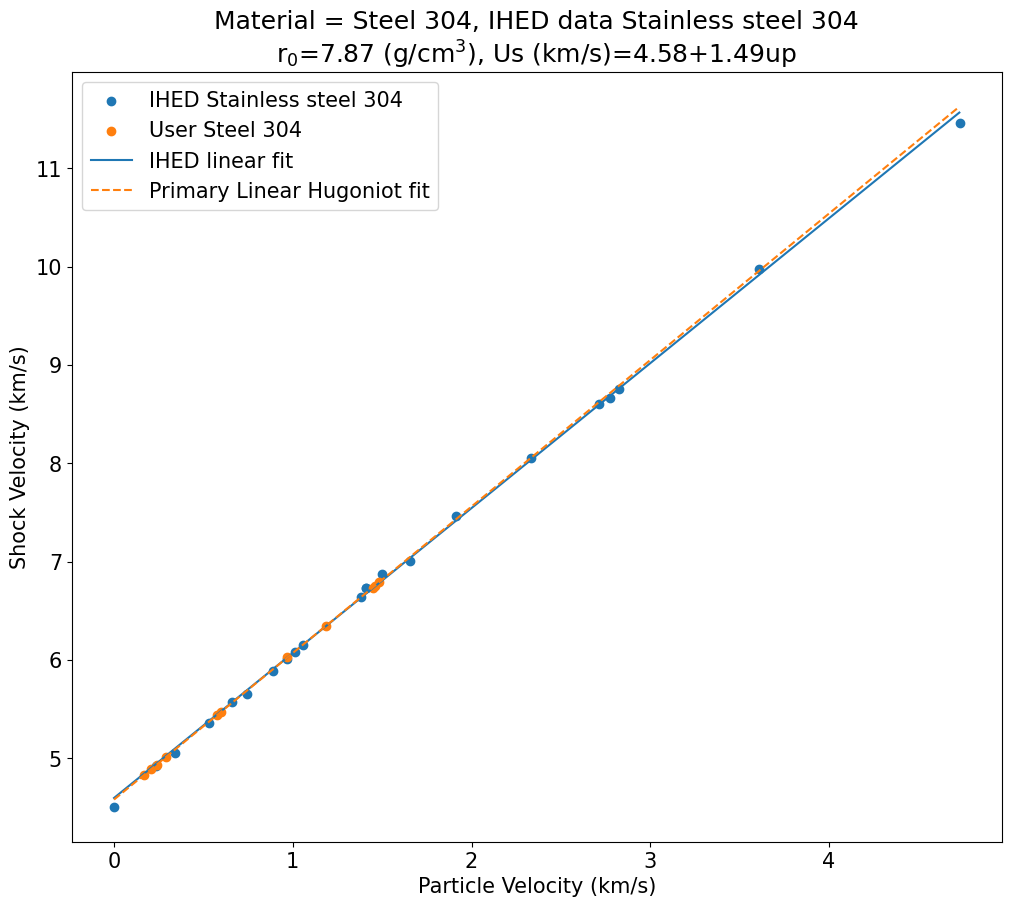

In [9]:
mat1.GetIHED(moredata=moredata)
mat1.PlotIHED()

In [10]:
print(mat1.ihed.uparr)

[1497. 2824. 3607. 4730.    0.  232.  339.  529.  659.  745.  889.  969.
 1010. 1057. 1383. 1409. 1409. 1653. 1915. 2334. 2711. 2772.]


linear fit and covariance matrix:
(array([1.49049663e+00, 4.57920929e+03]), array([[ 2.85192390e-05, -3.54779333e-02],
       [-3.54779333e-02,  6.52812465e+01]]))
min up =  170.0
max up =  3607.0
quadratic fit and covariance matrix:
(array([-4.19485703e-06,  1.50425650e+00,  4.57169415e+03]), array([[ 2.69935130e-11, -8.85434802e-08,  4.83592677e-05],
       [-8.85434802e-08,  3.19303958e-04, -1.94535898e-01],
       [ 4.83592677e-05, -1.94535898e-01,  1.52710713e+02]]))
min up =  170.0
max up =  3607.0


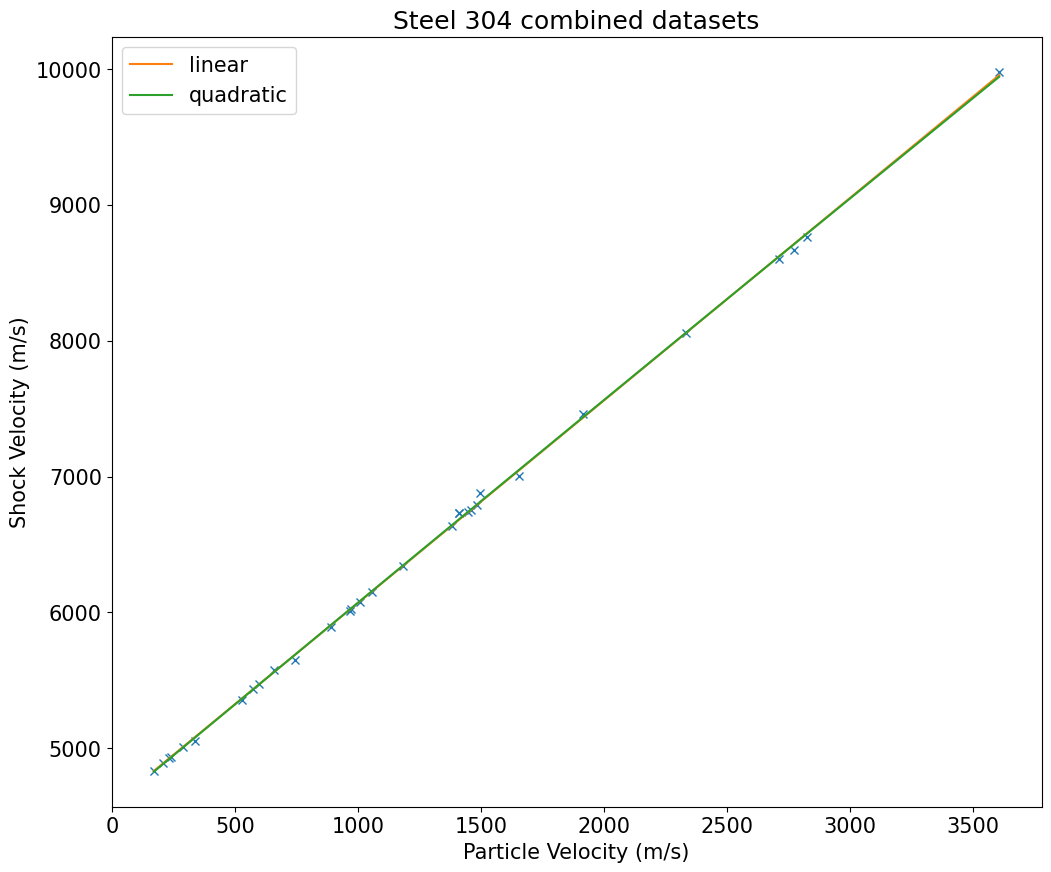

In [11]:
# combine datasets
# do not include the zero value from IHED
# do not include the maximum value
ind = np.where((mat1.ihed.uparr > 0.) & (mat1.ihed.uparr < 4000.))
up1 = mat1.ihed.uparr[ind]
us1 = mat1.ihed.usarr[ind]
upall = np.concatenate((up1,duffy_up))
usall = np.concatenate((us1,duffy_us))
plt.plot(upall,usall,'x')

# linear fit
fitparams = IM.FitUsUp(upall,usall,formflag=1,returncov=True)
res=fitparams[0]
supall = np.sort(upall)
plt.plot(supall,res[1]+res[0]*supall,'-',label='linear')
print('linear fit and covariance matrix:')
print(fitparams)
print('min up = ',min(supall))
print('max up = ',max(supall))

# quadratic fit same without the end points; use the linear fit
fitparams = IM.FitUsUp(upall,usall,formflag=2,returncov=True)
res=fitparams[0]
supall = np.sort(upall)
plt.plot(supall,res[2]+res[1]*supall+res[0]*supall**2,'-',label='quadratic')
print('quadratic fit and covariance matrix:')
print(fitparams)
print('min up = ',min(supall))
print('max up = ',max(supall))

plt.xlabel('Particle Velocity (m/s)')
plt.ylabel('Shock Velocity (m/s)')
plt.title('Steel 304 combined datasets')
plt.legend()


In [12]:
mat4 = IM.Material() # create material object named mat4
matname='Steel304-l2' # material name in the material-data.csv file
mat4.DefineParamsID(matname,matdata,imat) # load the parameters for this material
mat4.MakeHugoniot(up)


Including user data
Stainless steel 304 Steel304-l2 fit (mks) c0= 4596.26887151552  s1= 1.4739547307133403  s2= 0.0  d= 0.0
N=33. Fit stdev (km/s)=0.03705410249225906
Primary Hugoniot parameters c0,s1,s2,d= 4580.0 1.49 0.0 0.0


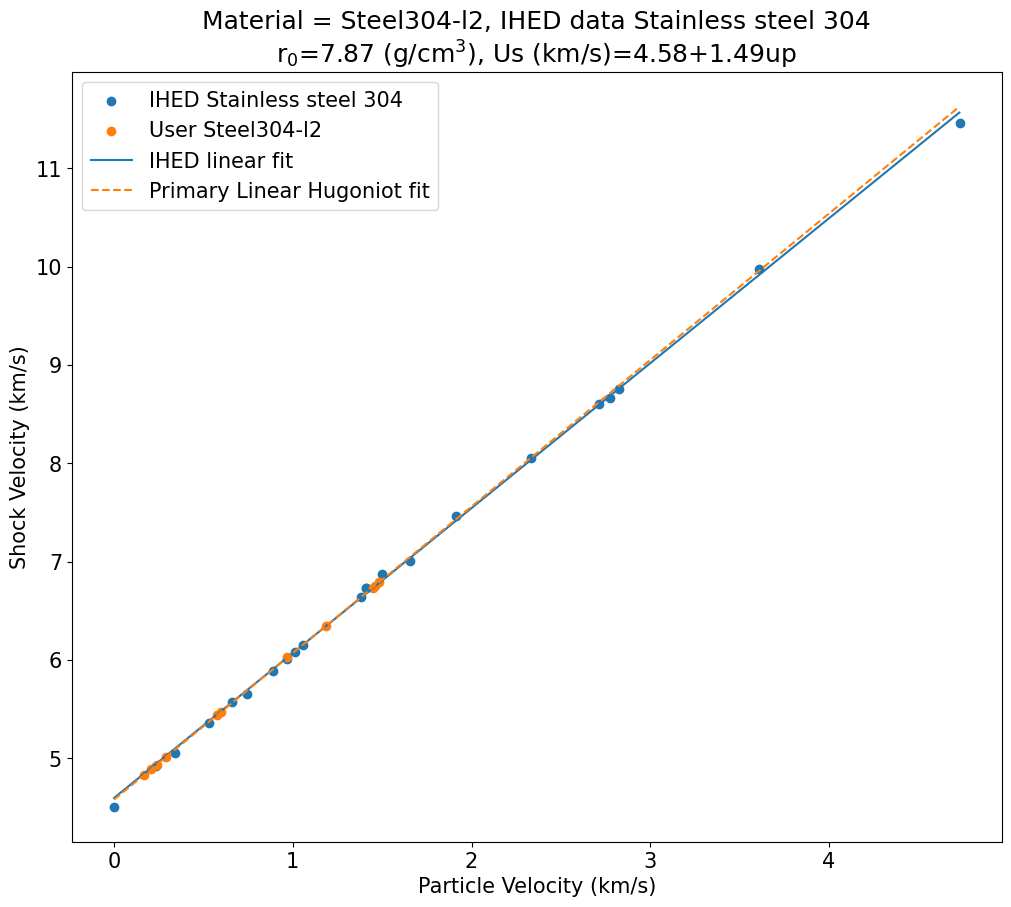

In [13]:
mat4.GetIHED(moredata=moredata)
mat4.PlotIHED()

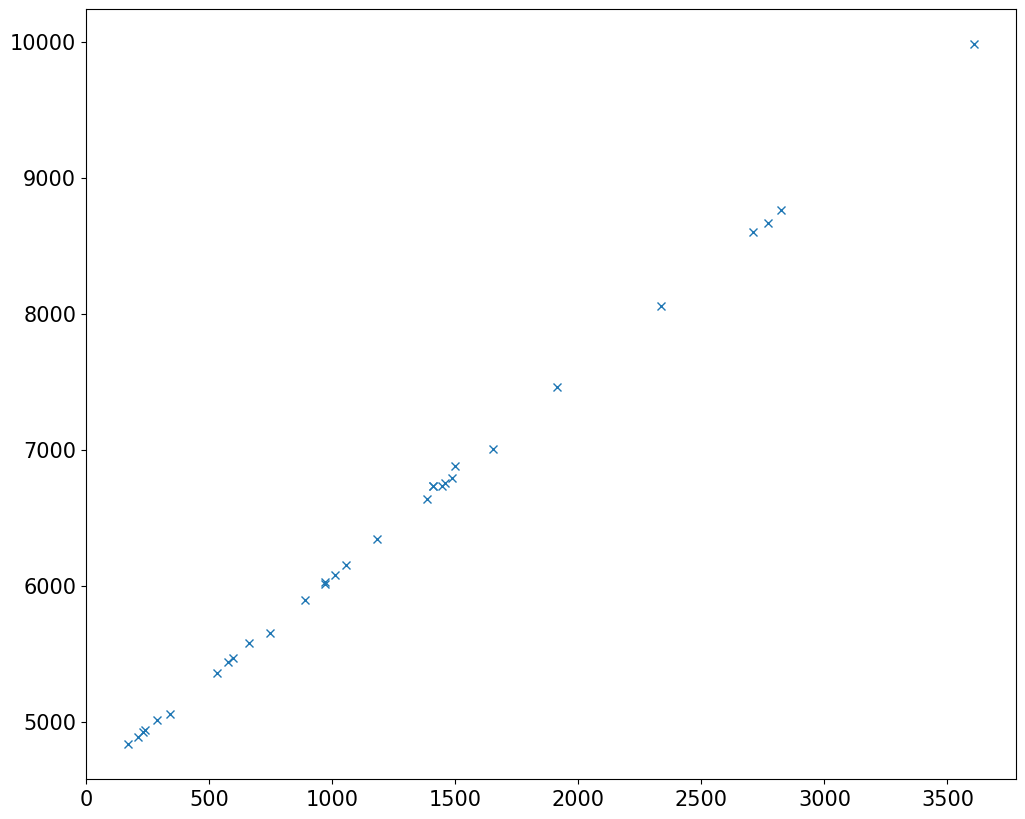

In [14]:
ind = np.where((mat1.ihed.uparr > 0.) & (mat1.ihed.uparr < 4000.))
up1 = mat1.ihed.uparr[ind]
us1 = mat1.ihed.usarr[ind]
upall = np.concatenate((up1,duffy_up))
usall = np.concatenate((us1,duffy_us))
plt.plot(upall,usall,'x')
